# CART Decision Tree for rest_int Classification

**Target:** `rest_int` (0: 1min, 1: 5min, 2: 10min rest)

**Data split:**
- **Train + Val**: For Grid Search with StratifiedKFold CV (validation during tuning)
- **Test**: Held out by `user_id` — never seen during training or tuning; used only for final evaluation
- **MCCV**: Monte Carlo CV — randomly select test users 10 times, average performance across runs

**Method:**
- Scikit-learn CART via `DecisionTreeClassifier`
- StratifiedKFold for hyperparameter tuning
- Grid Search over hyperparameters
- MCCV: 10 random train/test splits by user_id, report mean ± std of weighted F1
- **Frequency band ranking**: Train 21 trees, each time remove the most important feature (RFE-style) to rank bands


In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.tree import DecisionTreeClassifier
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.metrics import f1_score, classification_report, confusion_matrix

In [9]:
# Load data
df = pd.read_csv("dataset_filtered_bands.csv")

# Target and features
meta_cols = ["user_id", "rest_int", "exp", "seq"]
feature_cols = [c for c in df.columns if c not in meta_cols]
unique_users = df["user_id"].unique()
n_users = len(unique_users)

# MCCV config: ~80% train, ~20% test by user_id (11 and 3 users)
# Use fixed counts to match original split
n_train_users = int(n_users * 0.8)  # 11
n_test_users = n_users - n_train_users  # 3

print(f"Total: {n_users} users, {len(df)} samples")
print(f"MCCV split: {n_train_users} train users, {n_test_users} test users per run")

Total: 14 users, 243 samples
MCCV split: 11 train users, 3 test users per run


In [10]:
# MCCV: 10 random train/test splits by user_id
N_MCCV = 10
MCCV_SEEDS = list(range(42, 42 + N_MCCV))  # 42, 43, ..., 51

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
param_grid = {
    "max_depth": [3, 5, 7, 10, None],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 5],
    "max_features": ["sqrt", "log2", None],
    "criterion": ["gini", "entropy", "log_loss"],
}

# Store metrics across MCCV runs
mccv_f1 = []
mccv_acc = []
mccv_cm_list = []
best_params_seed42 = None  # save for ranking section (same split)

for run, seed in enumerate(MCCV_SEEDS):
    # Random train/test split by user_id
    np.random.seed(seed)
    shuffled_users = np.random.permutation(unique_users)
    train_users = shuffled_users[:n_train_users]
    test_users = shuffled_users[n_train_users:]

    train_mask = df["user_id"].isin(train_users)
    test_mask = df["user_id"].isin(test_users)
    df_train = df[train_mask]
    df_test = df[test_mask]

    X_train = df_train[feature_cols].values
    y_train = df_train["rest_int"].values
    X_test = df_test[feature_cols].values
    y_test = df_test["rest_int"].values

    # Grid Search
    clf = DecisionTreeClassifier(random_state=42)
    grid_search = GridSearchCV(
        clf, param_grid, cv=cv, scoring="f1_weighted", n_jobs=-1, verbose=0
    )
    grid_search.fit(X_train, y_train)

    # Evaluate on test set
    y_pred = grid_search.best_estimator_.predict(X_test)
    f1 = f1_score(y_test, y_pred, average="weighted")
    acc = (y_pred == y_test).mean()
    cm = confusion_matrix(y_test, y_pred)

    mccv_f1.append(f1)
    mccv_acc.append(acc)
    mccv_cm_list.append(cm)

    if seed == 42:
        best_params_seed42 = grid_search.best_params_.copy()
        print(f"Run {run+1}/{N_MCCV} (seed={seed}): F1={f1:.4f}, Acc={acc:.4f}  [best params saved for ranking]")
    else:
        print(f"Run {run+1}/{N_MCCV} (seed={seed}): F1={f1:.4f}, Acc={acc:.4f}")

Run 1/10 (seed=42): F1=0.2099, Acc=0.2353  [best params saved for ranking]
Run 2/10 (seed=43): F1=0.1991, Acc=0.2222
Run 3/10 (seed=44): F1=0.1852, Acc=0.1852
Run 4/10 (seed=45): F1=0.2960, Acc=0.3148
Run 5/10 (seed=46): F1=0.2505, Acc=0.2963
Run 6/10 (seed=47): F1=0.1731, Acc=0.1765
Run 7/10 (seed=48): F1=0.3057, Acc=0.2963
Run 8/10 (seed=49): F1=0.3052, Acc=0.3333
Run 9/10 (seed=50): F1=0.3241, Acc=0.3333
Run 10/10 (seed=51): F1=0.3072, Acc=0.3529


In [11]:
# MCCV summary: mean ± std across 10 runs
print("Best params (seed=42, used for ranking below):", best_params_seed42)
print("\n--- MCCV Results (10 random train/test splits by user_id) ---")
print(f"Weighted F1: {np.mean(mccv_f1):.4f} ± {np.std(mccv_f1):.4f}")
print(f"Accuracy:     {np.mean(mccv_acc):.4f} ± {np.std(mccv_acc):.4f}")

# Mean confusion matrix (element-wise average)
mean_cm = np.mean(mccv_cm_list, axis=0).round(1)
print("\n--- Mean Confusion Matrix (across 10 runs) ---")
print(mean_cm)
print("(rows: 1min, 5min, 10min; cols: predicted)")

Best params (seed=42, used for ranking below): {'criterion': 'entropy', 'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'min_samples_split': 2}

--- MCCV Results (10 random train/test splits by user_id) ---
Weighted F1: 0.2556 ± 0.0557
Accuracy:     0.2746 ± 0.0612

--- Mean Confusion Matrix (across 10 runs) ---
[[6.  5.3 6.1]
 [6.3 3.9 7.2]
 [6.3 7.1 4.6]]
(rows: 1min, 5min, 10min; cols: predicted)


## Comparison 1: With PCA vs Without PCA

MCCV 10 runs, paired comparison. Bar chart with significance (paired t-test).

Total PCs (max): 21
PCs to capture 80% variance: 2
Actual variance at 2 PCs: 0.8526


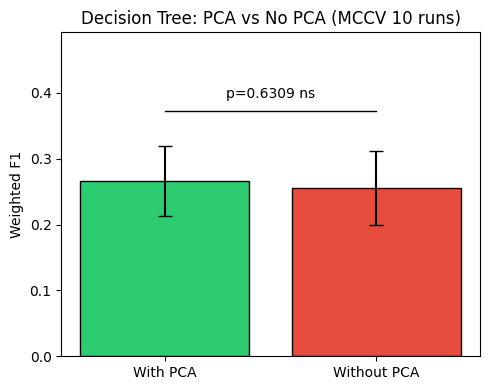

With PCA:  0.2664 ± 0.0532
Without PCA: 0.2556 ± 0.0557
Paired t-test: p = 0.6309 ns


In [12]:
# PCA vs Without PCA: MCCV 10 runs
# PCA exploration: total PCs and 80% variance before grid search
X_full = df[feature_cols].values
X_scaled = StandardScaler().fit_transform(X_full)
max_pc = min(len(feature_cols), len(df) - 1)
pca_explore = PCA(n_components=max_pc, random_state=42).fit(X_scaled)
cumvar = np.cumsum(pca_explore.explained_variance_ratio_)
n_pc_80 = np.searchsorted(cumvar, 0.8) + 1  # 1-based count for 80% variance
print(f"Total PCs (max): {max_pc}")
print(f"PCs to capture 80% variance: {n_pc_80}")
print(f"Actual variance at {n_pc_80} PCs: {cumvar[n_pc_80-1]:.4f}")

n_pc_max = min(n_pc_80, 20, max_pc)
n_components_options = [n for n in [2, 3, 4, 5, 10, 15, 20] if n <= n_pc_max]
if n_pc_max > 20 and n_pc_max not in n_components_options:
    n_components_options.append(n_pc_max)
    n_components_options.sort()
if not n_components_options:
    n_components_options = [min(10, max_pc)]

pipe_with_pca = Pipeline([
    ("scaler", StandardScaler()),
    ("pca", PCA(random_state=42)),
    ("tree", DecisionTreeClassifier(random_state=42)),
])
param_with_pca = {
    "pca__n_components": n_components_options,
    "tree__max_depth": [3, 5, 7, 10, None],
    "tree__min_samples_split": [2, 5, 10],
    "tree__min_samples_leaf": [1, 2, 5],
    "tree__max_features": ["sqrt", "log2", None],
    "tree__criterion": ["gini", "entropy", "log_loss"],
}

f1_with_pca, f1_no_pca = [], []
for run, seed in enumerate(MCCV_SEEDS):
    np.random.seed(seed)
    shuffled_users = np.random.permutation(unique_users)
    train_users = shuffled_users[:n_train_users]
    test_users = shuffled_users[n_train_users:]
    train_mask = df["user_id"].isin(train_users)
    test_mask = df["user_id"].isin(test_users)
    X_train = df[train_mask][feature_cols].values
    y_train = df[train_mask]["rest_int"].values
    X_test = df[test_mask][feature_cols].values
    y_test = df[test_mask]["rest_int"].values

    gs_pca = GridSearchCV(pipe_with_pca, param_with_pca, cv=cv, scoring="f1_weighted", n_jobs=-1, verbose=0)
    gs_pca.fit(X_train, y_train)
    f1_with_pca.append(f1_score(y_test, gs_pca.best_estimator_.predict(X_test), average="weighted"))

    clf_no = DecisionTreeClassifier(random_state=42)
    gs_no = GridSearchCV(clf_no, param_grid, cv=cv, scoring="f1_weighted", n_jobs=-1, verbose=0)
    gs_no.fit(X_train, y_train)
    f1_no_pca.append(f1_score(y_test, gs_no.best_estimator_.predict(X_test), average="weighted"))

# Paired t-test
t_stat, p_val = stats.ttest_rel(f1_with_pca, f1_no_pca)
sig = "***" if p_val < 0.001 else "**" if p_val < 0.01 else "*" if p_val < 0.05 else "ns"

# Bar chart with significance
fig, ax = plt.subplots(figsize=(5, 4))
x = np.arange(2)
means = [np.mean(f1_with_pca), np.mean(f1_no_pca)]
stds = [np.std(f1_with_pca), np.std(f1_no_pca)]
ax.bar(x, means, yerr=stds, capsize=5, color=["#2ecc71", "#e74c3c"], edgecolor="black")
ax.set_xticks(x)
ax.set_xticklabels(["With PCA", "Without PCA"])
ax.set_ylabel("Weighted F1")
ax.set_title("Decision Tree: PCA vs No PCA (MCCV 10 runs)")
ymax = max(means) + max(stds) + 0.05
ax.plot([0, 1], [ymax, ymax], "k-", lw=1)
ax.text(0.5, ymax + 0.02, f"p={p_val:.4f} {sig}", ha="center", fontsize=10)
ax.set_ylim(0, ymax + 0.12)
plt.tight_layout()
plt.show()
print(f"With PCA:  {np.mean(f1_with_pca):.4f} ± {np.std(f1_with_pca):.4f}")
print(f"Without PCA: {np.mean(f1_no_pca):.4f} ± {np.std(f1_no_pca):.4f}")
print(f"Paired t-test: p = {p_val:.4f} {sig}")

## Comparison 2: Subject-specific vs Generalized Models

- **Generalized**: Train on 11 users, test on 3 held-out users
- **Subject-specific**: For each test user, train only on that user's data (with CV), test on held-out portion

/Users/shikaiyi/miniforge3/envs/Neural/lib/python3.13/site-packages/sklearn/model_selection/_split.py:813: UserWarning: The least populated class in y has only 1 members, which is less than n_splits=2.
  warnings.warn(
/Users/shikaiyi/miniforge3/envs/Neural/lib/python3.13/site-packages/sklearn/model_selection/_split.py:813: UserWarning: The least populated class in y has only 1 members, which is less than n_splits=2.
  warnings.warn(
/Users/shikaiyi/miniforge3/envs/Neural/lib/python3.13/site-packages/sklearn/model_selection/_split.py:813: UserWarning: The least populated class in y has only 1 members, which is less than n_splits=2.
  warnings.warn(
/Users/shikaiyi/miniforge3/envs/Neural/lib/python3.13/site-packages/sklearn/model_selection/_split.py:813: UserWarning: The least populated class in y has only 1 members, which is less than n_splits=2.
  warnings.warn(


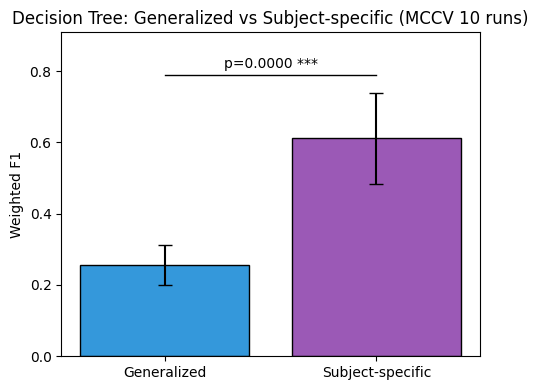

Generalized: 0.2556 ± 0.0557
Subject-specific: 0.6113 ± 0.1276
Paired t-test: p = 0.0000 ***


In [13]:
# Subject-specific vs Generalized: MCCV 10 runs
f1_generalized, f1_subject_specific = [], []
for run, seed in enumerate(MCCV_SEEDS):
    np.random.seed(seed)
    shuffled_users = np.random.permutation(unique_users)
    train_users = shuffled_users[:n_train_users]
    test_users = shuffled_users[n_train_users:]

    # Generalized
    train_mask = df["user_id"].isin(train_users)
    test_mask = df["user_id"].isin(test_users)
    X_train_g = df[train_mask][feature_cols].values
    y_train_g = df[train_mask]["rest_int"].values
    X_test_all = df[test_mask][feature_cols].values
    y_test_all = df[test_mask]["rest_int"].values
    clf_g = DecisionTreeClassifier(random_state=42)
    gs_g = GridSearchCV(clf_g, param_grid, cv=cv, scoring="f1_weighted", n_jobs=-1, verbose=0)
    gs_g.fit(X_train_g, y_train_g)
    f1_generalized.append(f1_score(y_test_all, gs_g.best_estimator_.predict(X_test_all), average="weighted"))

    # Subject-specific
    f1_per_user = []
    for uid in test_users:
        df_u = df[df["user_id"] == uid]
        X_u = df_u[feature_cols].values
        y_u = df_u["rest_int"].values
        if len(y_u) < 6:
            f1_per_user.append(0.0)
            continue
        n_splits = min(3, len(y_u) // 6) or 2
        skf_u = StratifiedKFold(n_splits=max(2, n_splits), shuffle=True, random_state=42)
        preds, truths = [], []
        for tr_idx, te_idx in skf_u.split(X_u, y_u):
            clf_u = DecisionTreeClassifier(random_state=42)
            gs_u = GridSearchCV(clf_u, param_grid, cv=2, scoring="f1_weighted", n_jobs=-1, verbose=0)
            gs_u.fit(X_u[tr_idx], y_u[tr_idx])
            preds.extend(gs_u.best_estimator_.predict(X_u[te_idx]))
            truths.extend(y_u[te_idx])
        f1_per_user.append(f1_score(truths, preds, average="weighted"))
    f1_subject_specific.append(np.mean(f1_per_user))

# Paired t-test
t_stat, p_val = stats.ttest_rel(f1_generalized, f1_subject_specific)
sig = "***" if p_val < 0.001 else "**" if p_val < 0.01 else "*" if p_val < 0.05 else "ns"

# Bar chart
fig, ax = plt.subplots(figsize=(5, 4))
x = np.arange(2)
means = [np.mean(f1_generalized), np.mean(f1_subject_specific)]
stds = [np.std(f1_generalized), np.std(f1_subject_specific)]
ax.bar(x, means, yerr=stds, capsize=5, color=["#3498db", "#9b59b6"], edgecolor="black")
ax.set_xticks(x)
ax.set_xticklabels(["Generalized", "Subject-specific"])
ax.set_ylabel("Weighted F1")
ax.set_title("Decision Tree: Generalized vs Subject-specific (MCCV 10 runs)")
ymax = max(means) + max(stds) + 0.05
ax.plot([0, 1], [ymax, ymax], "k-", lw=1)
ax.text(0.5, ymax + 0.02, f"p={p_val:.4f} {sig}", ha="center", fontsize=10)
ax.set_ylim(0, ymax + 0.12)
plt.tight_layout()
plt.show()
print(f"Generalized: {np.mean(f1_generalized):.4f} ± {np.std(f1_generalized):.4f}")
print(f"Subject-specific: {np.mean(f1_subject_specific):.4f} ± {np.std(f1_subject_specific):.4f}")
print(f"Paired t-test: p = {p_val:.4f} {sig}")

In [14]:
# Save results for model comparison
import json
import os

os.makedirs("model_results", exist_ok=True)
results = {
    "model": "decision_tree",
    "f1_with_pca": [float(x) for x in f1_with_pca],
    "f1_no_pca": [float(x) for x in f1_no_pca],
    "f1_generalized": [float(x) for x in f1_generalized],
    "f1_subject_specific": [float(x) for x in f1_subject_specific],
}
with open("model_results/decision_tree_results.json", "w") as f:
    json.dump(results, f, indent=2)
print("Saved decision_tree results to model_results/decision_tree_results.json")

Saved decision_tree results to model_results/decision_tree_results.json


## Frequency Band Importance Ranking (RFE-style)

Train 21 trees; each iteration remove the most important feature. First removed = most important, last remaining = least important.

In [15]:
# RFE-style frequency band ranking: train 21 trees, remove most important each time
np.random.seed(42)
shuffled_users = np.random.permutation(unique_users)
train_users = shuffled_users[:n_train_users]
train_mask = df["user_id"].isin(train_users)
X_train_rank = df[train_mask][feature_cols].values
y_train_rank = df[train_mask]["rest_int"].values

# Reuse best params from MCCV run with seed=42 (same train split)
tree_params = {**best_params_seed42, "random_state": 42}

remaining = list(feature_cols)  # start with all 21 features
ranking = []  # 1st appended = most important, last = least important

for step in range(len(feature_cols)):
    X = df[train_mask][remaining].values
    clf = DecisionTreeClassifier(**tree_params)
    clf.fit(X, y_train_rank)
    imp = clf.feature_importances_
    idx_top = np.argmax(imp)
    removed = remaining.pop(idx_top)
    ranking.append(removed)
    print(f"Tree {step+1}/21: removed {removed} (importance={imp[idx_top]:.4f}), {len(remaining)} left")

# Final ranking: 1 = most important, 21 = least important
rank_df = pd.DataFrame({"rank": range(1, len(ranking) + 1), "feature": ranking})
print("\n--- Frequency Band Importance Ranking (1=most, 21=least) ---")
print(rank_df.to_string(index=False))

Tree 1/21: removed ch_2_band_7 (importance=0.1177), 20 left
Tree 2/21: removed ch_3_band_6 (importance=0.1022), 19 left
Tree 3/21: removed ch_2_band_5 (importance=0.1377), 18 left
Tree 4/21: removed ch_3_band_7 (importance=0.1148), 17 left
Tree 5/21: removed ch_1_band_7 (importance=0.1340), 16 left
Tree 6/21: removed ch_1_band_6 (importance=0.1542), 15 left
Tree 7/21: removed ch_3_band_4 (importance=0.2089), 14 left
Tree 8/21: removed ch_2_band_6 (importance=0.1764), 13 left
Tree 9/21: removed ch_1_band_4 (importance=0.1494), 12 left
Tree 10/21: removed ch_3_band_5 (importance=0.1790), 11 left
Tree 11/21: removed ch_3_band_2 (importance=0.1445), 10 left
Tree 12/21: removed ch_2_band_4 (importance=0.1615), 9 left
Tree 13/21: removed ch_1_band_5 (importance=0.1863), 8 left
Tree 14/21: removed ch_3_band_1 (importance=0.2251), 7 left
Tree 15/21: removed ch_3_band_3 (importance=0.2483), 6 left
Tree 16/21: removed ch_2_band_3 (importance=0.2654), 5 left
Tree 17/21: removed ch_2_band_2 (impor